# TP02 — VAE, GAN et mode collapse
Réalisation des exercices E1–E4 du TP02 ECE, intégrée au dépôt FraudLab.
Scénarios synthétiques uniquement. On calcule des mécanismes ; on ne prétend pas avoir entraîné un VAE ou un GAN bancaire.
Exécution : `python scripts/execute_course_notebooks.py`. Figures et preuve dans `experiments/tp02/`.
Réalisation assistée par Codex ; contributions humaines à décider.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
SEED = 1729
print('NumPy', np.__version__, '| seed', SEED)
def verifier(numero, condition, commentaire=''):
    assert bool(condition), f'{numero} : {commentaire}'
    print(f'{numero} : vérification réussie. {commentaire}')


NumPy 2.5.5 | seed 1729


## E1 — Reparamétrisation VAE

In [2]:
def reparametrer(mu,logvar,eps):
    return np.asarray(mu)+np.exp(.5*np.asarray(logvar))*np.asarray(eps)
mu=np.array([2.,0.]);logvar=np.log(np.array([.25,1.]));eps=np.array([-1.,.5])
z=reparametrer(mu,logvar,eps)
print('z =',z)
verifier('E1',np.allclose(z,[1.5,.5]))


z = [1.5 0.5]
E1 : vérification réussie. 


logvar représente le logarithme de la variance. Le facteur exp(0,5 logvar) est l’écart-type. Le bruit epsilon est fixé pour pouvoir vérifier le calcul.

## E2 — KL gaussienne vers le prior standard

In [3]:
def kl_standard(mu,logvar):
    mu=np.asarray(mu);logvar=np.asarray(logvar)
    return float(.5*np.sum(mu**2+np.exp(logvar)-logvar-1))
kl_prior=kl_standard(np.zeros(2),np.zeros(2))
kl_decale=kl_standard(np.array([1.,0.]),np.zeros(2))
print('KL prior =',kl_prior,'KL décalée =',kl_decale)
verifier('E2',abs(kl_prior)<1e-9 and abs(kl_decale-.5)<1e-9)


KL prior = 0.0 KL décalée = 0.5
E2 : vérification réussie. 


La KL vaut zéro quand le posterior testé égale le prior. Décaler une moyenne tout en conservant une variance unitaire donne ici 0,5 nat. Cette pénalité ne mesure pas seule la qualité de reconstruction.

## E3 — Pertes adversariales

In [4]:
def perte_D(p_reel,p_faux):
    reel=np.clip(np.asarray(p_reel,dtype=float),1e-8,1-1e-8)
    faux=np.clip(np.asarray(p_faux,dtype=float),1e-8,1-1e-8)
    return float(-np.mean(np.log(reel))-np.mean(np.log(1-faux)))
def perte_G(p_faux):
    faux=np.clip(np.asarray(p_faux,dtype=float),1e-8,1-1e-8)
    return float(-np.mean(np.log(faux)))
reel=np.array([.9,.8,.95]);faux=np.array([.2,.1,.3])
loss_d=perte_D(reel,faux);loss_g=perte_G(faux)
print('Perte D =',loss_d,'Perte G =',loss_g)
verifier('E3',.2<loss_d<.6 and 1.4<loss_g<2.3)
assert np.isfinite(perte_D([0,1],[1,0])) and np.isfinite(perte_G([0,1]))


Perte D = 0.3549921240901184 Perte G = 1.7053319365846937
E3 : vérification réussie. 


Le discriminateur distingue assez bien les exemples de ce scénario, donc sa perte est faible et celle du générateur élevée. Le clipping évite log(0), sans prouver convergence ni diversité.

## E4 — Diagnostic de couverture

Couverture B référence = 0.3 générateur = 0.0


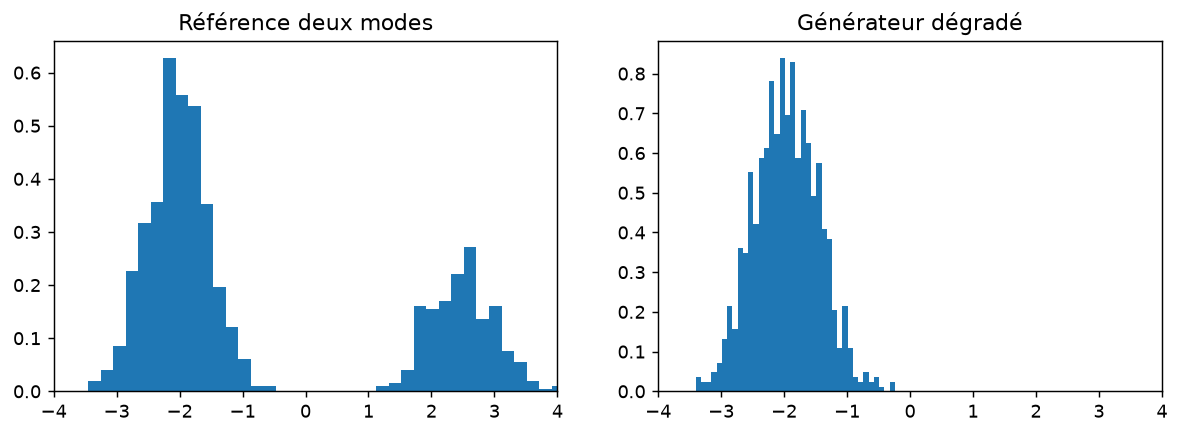

In [5]:
rng=np.random.default_rng(SEED)
ref=np.r_[rng.normal(-2,.5,700),rng.normal(2.5,.5,300)]
mode_collapse=rng.normal(-2,.5,1000)
fig,axs=plt.subplots(1,2,figsize=(11,3.5))
for ax,vals,name in [(axs[0],ref,'Référence deux modes'),(axs[1],mode_collapse,'Générateur dégradé')]:
    ax.hist(vals,bins=38,density=True);ax.set_xlim(-4,4);ax.set_title(name)
plt.show()
coverage_ref=float(np.mean(ref>1));coverage_bad=float(np.mean(mode_collapse>1))
print('Couverture B référence =',coverage_ref,'générateur =',coverage_bad)
assert .25<coverage_ref<.35 and coverage_bad<.02


### Réponse E4
1. Le phénomène observé est un **mode collapse** : le générateur dégradé ne couvre qu’une des deux sous-populations, malgré des exemples localement plausibles.
2. Le mode rare représente environ **30 %** de la référence et presque **0 %** des sorties dégradées. Les valeurs exactes mesurées figurent dans la sortie de la cellule.
3. Ne pas utiliser ce générateur pour représenter les événements rares sans correction et nouvelle évaluation sur une référence indépendante. Contrôler couverture par segment, fidélité et utilité aval ; une perte favorable ne suffit pas.

### Questions de réflexion
- **VAE versus bruit GAN :** dans le VAE, epsilon est transformé par un posterior dépendant de l’entrée, via mu et sigma, pour permettre un gradient sur ces paramètres. Dans le GAN, z est tiré d’un prior d’entrée et transformé directement par G ; il n’existe pas nécessairement d’encodeur ni de terme KL.
- **Pourquoi les pertes seules ne suffisent pas :** elles décrivent l’objectif du jeu d’apprentissage, pas la couverture des populations ni l’utilité. Le mode collapse fournit le contre-exemple. Ajouter inspection, métriques de distribution/couverture et test réel indépendant.

### Lien avec FraudLab
Ces mécanismes justifient l’examen de la diversité et des alternatives génératives. Le projet final a retenu le DDPM : ce TP ne constitue pas un benchmark VAE/GAN entraîné sur transactions. Références : Kingma et Welling (2013), arXiv:1312.6114 ; Goodfellow et al. (2014), arXiv:1406.2661. Support étudiant ECE fourni, non redistribué intégralement.
